In [39]:
# Librerias a importar
import os
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV, RepeatedStratifiedKFold, RepeatedKFold
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
# Modelos
from xgboost import XGBClassifier
# Métricas
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay, confusion_matrix, mean_squared_error, mean_absolute_error, r2_score

import matplotlib.pyplot as plt

In [2]:
# Montar drive
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


#Parte 1: Carga y Exploración Inicial de Datos
Cargar el dataset

In [3]:
# Importar DataFrame
path = '/content/drive/MyDrive/Colab Notebooks/Modelos Regresión/dataset/heart_disease_uci.csv'
data = pd.read_csv(path, sep=',')

Realizar una exploración inicial para entender la estructura del dataset

In [4]:
# Exploración de datos
print(data.head())
print(data.describe())

   id  age     sex    dataset               cp  trestbps   chol    fbs  \
0   1   63    Male  Cleveland   typical angina     145.0  233.0   True   
1   2   67    Male  Cleveland     asymptomatic     160.0  286.0  False   
2   3   67    Male  Cleveland     asymptomatic     120.0  229.0  False   
3   4   37    Male  Cleveland      non-anginal     130.0  250.0  False   
4   5   41  Female  Cleveland  atypical angina     130.0  204.0  False   

          restecg  thalch  exang  oldpeak        slope   ca  \
0  lv hypertrophy   150.0  False      2.3  downsloping  0.0   
1  lv hypertrophy   108.0   True      1.5         flat  3.0   
2  lv hypertrophy   129.0   True      2.6         flat  2.0   
3          normal   187.0  False      3.5  downsloping  0.0   
4  lv hypertrophy   172.0  False      1.4    upsloping  0.0   

                thal  num  
0       fixed defect    0  
1             normal    2  
2  reversable defect    1  
3             normal    0  
4             normal    0  
        

##Parte 2: Análisis Exploratorio de Datos (EDA)
Limpieza de Datos:

In [29]:
# Hacemos copia del DataFrame
df=data.copy()

# Convertimos a minúsculas y quitamos espacios en blanco de las columnas
df.columns = df.columns.str.lower().str.strip()

# Convertimos a minúsculas y quitamos espacios en blanco de las columnas de tipo objeto
# for col in df.columns:
#   if df[col].dtype == 'object':
#      df[col] = df[col].str.lower().str.strip()

Eliminar columnas innecesarias para el estudio

In [30]:
# Se identificó la columna 'id' para eliminar, por no aportar al estudio
df = df.drop('id', axis=1)
print("Columna 'id' eliminada.")

Columna 'id' eliminada.


Definición de columnas numéricas y categóricas

In [31]:
categorical_cols = []
numerical_cols = []

for col in df.columns:
    if df[col].dtype == 'object':
        categorical_cols.append(col)
    else:
        numerical_cols.append(col)

print("Columnas numéricas:", numerical_cols)
print("Columnas categóricas:", categorical_cols)


Columnas numéricas: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', 'num']
Columnas categóricas: ['sex', 'dataset', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']


##Descripción del Conjunto de Datos:
Breve descripción de cada conjunto de datos, incluyendo la fuente, el tamaño y las variables.

In [20]:
print(f"\nEl conjunto de datos: {os.path.basename(path)}, proviene de https://www.kaggle.com/datasets/alihamza01/heart-disease-uci y se carga desde Google Drive.")
print(f"\nTamaño: El tamaño del archivo es {os.path.getsize(path)/1000} kb, el número de filas es de {df.shape[0]} y el número de columnas es de {df.shape[1]}.")
print(f"\nVariables: Las variables numérica están conformadas por: {'Sin variables numéricas' if not numerical_cols else ', '.join(numerical_cols)} y las variables categóricas por: {'Sin variables categóricas' if not categorical_cols else ', '.join(categorical_cols)}")


El conjunto de datos: heart_disease_uci.csv, proviene de https://www.kaggle.com/datasets/alihamza01/heart-disease-uci y se carga desde Google Drive.

Tamaño: El tamaño del archivo es 79.346 kb, el número de filas es de 920 y el número de columnas es de 15.

Variables: Las variables numérica están conformadas por: age, trestbps, chol, thalch, oldpeak, ca, num y las variables categóricas por: sex, dataset, cp, fbs, restecg, exang, slope, thal


Identificar valores faltantes

In [21]:
# Verificar por datos nulos
datos_null = df.isnull()
if datos_null.any().any():
    print("Cantidad de datos nulos por columna:\n", datos_null.sum())
else:
    print("No se encontró datos nulos")

Cantidad de datos nulos por columna:
 age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64


Verificar tipos de datos en columnas

In [22]:
# Se identificó datos correctos en columnas
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       920 non-null    int64  
 1   sex       920 non-null    object 
 2   dataset   920 non-null    object 
 3   cp        920 non-null    object 
 4   trestbps  861 non-null    float64
 5   chol      890 non-null    float64
 6   fbs       830 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    865 non-null    float64
 9   exang     865 non-null    object 
 10  oldpeak   858 non-null    float64
 11  slope     611 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       920 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 107.9+ KB
None


Identificar valores únicos

In [23]:
# Verificamos valores únicos en las columas
for col in df.columns:
    print(f"\nDatos en la columa: '{col}':")
    print(df[col].unique())


Datos en la columa: 'age':
[63 67 37 41 56 62 57 53 44 52 48 54 49 64 58 60 50 66 43 40 69 59 42 55
 61 65 71 51 46 45 39 68 47 34 35 29 70 77 38 74 76 28 30 31 32 33 36 72
 73 75]

Datos en la columa: 'sex':
['Male' 'Female']

Datos en la columa: 'dataset':
['Cleveland' 'Hungary' 'Switzerland' 'VA Long Beach']

Datos en la columa: 'cp':
['typical angina' 'asymptomatic' 'non-anginal' 'atypical angina']

Datos en la columa: 'trestbps':
[145. 160. 120. 130. 140. 172. 150. 110. 132. 117. 135. 112. 105. 124.
 125. 142. 128. 170. 155. 104. 180. 138. 108. 134. 122. 115. 118. 100.
 200.  94. 165. 102. 152. 101. 126. 174. 148. 178. 158. 192. 129. 144.
 123. 136. 146. 106. 156. 154. 114. 164.  98. 190.  nan 113.  92.  95.
  80. 185. 116.   0.  96. 127.]

Datos en la columa: 'chol':
[233. 286. 229. 250. 204. 236. 268. 354. 254. 203. 192. 294. 256. 263.
 199. 168. 239. 275. 266. 211. 283. 284. 224. 206. 219. 340. 226. 247.
 167. 230. 335. 234. 177. 276. 353. 243. 225. 302. 212. 330. 175. 417.
 1

Identificar inconsistencia en datos categóricos

In [ ]:
# No se identificaron datos con inconsistencia

Identificar valores duplicados

In [24]:
# Buscar datos duplicados
datos_duplicados = df.duplicated()
if datos_duplicados.any():
    print("Cantidad de datos duplicados: ", datos_duplicados.sum())
else:
    print("No se encontró datos duplicados")

Cantidad de datos duplicados:  2


Identificar valores outliers

In [25]:
# Función para identificar valores outliers usando el método IQR
def detect_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers

# Identificar outliers en columna numéricas
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

# Excluir la columna 'outcome'
if 'outcome' in numerical_columns:
  numerical_columns.remove('outcome')

print("\nIdentificar outliers usando el método IQR:")
for col in numerical_columns:
    outliers = detect_outliers_iqr(df, col)
    if not outliers.empty:
        print(f"Outliers en columna '{col}':")
        print(outliers[[col]])
        print("-" * 30)


Identificar outliers usando el método IQR:
Outliers en columna 'trestbps':
     trestbps
14      172.0
83      180.0
126     200.0
172     174.0
183     178.0
188     192.0
201     180.0
213     178.0
231     180.0
338     190.0
375     180.0
387     180.0
475     180.0
484     180.0
548     200.0
569     180.0
595     180.0
644      80.0
647     180.0
680     200.0
700     185.0
701     200.0
727     180.0
753       0.0
779     178.0
854     172.0
889     180.0
896     190.0
------------------------------
Outliers en columna 'chol':
      chol
48   417.0
152  564.0
181  409.0
373  412.0
434  468.0
..     ...
818    0.0
819    0.0
822    0.0
839    0.0
840    0.0

[183 rows x 1 columns]
------------------------------
Outliers en columna 'thalch':
     thalch
631    60.0
677    63.0
------------------------------
Outliers en columna 'oldpeak':
     oldpeak
91       6.2
121      4.0
123      5.6
126      4.0
183      4.2
191      4.2
211      3.8
285      4.4
293      4.0
567      4.0
5

In [ ]:
# Los datos outliers identificados se encuentran en las columnas de 'ca', 'oldpeak', 'thalch', 'chol' y 'trestbps'. No afectan el estudio, ya que es un dato particular de la muestra. No requiere ser tratado.

Crear visualizaciones univariadas y multivariadas

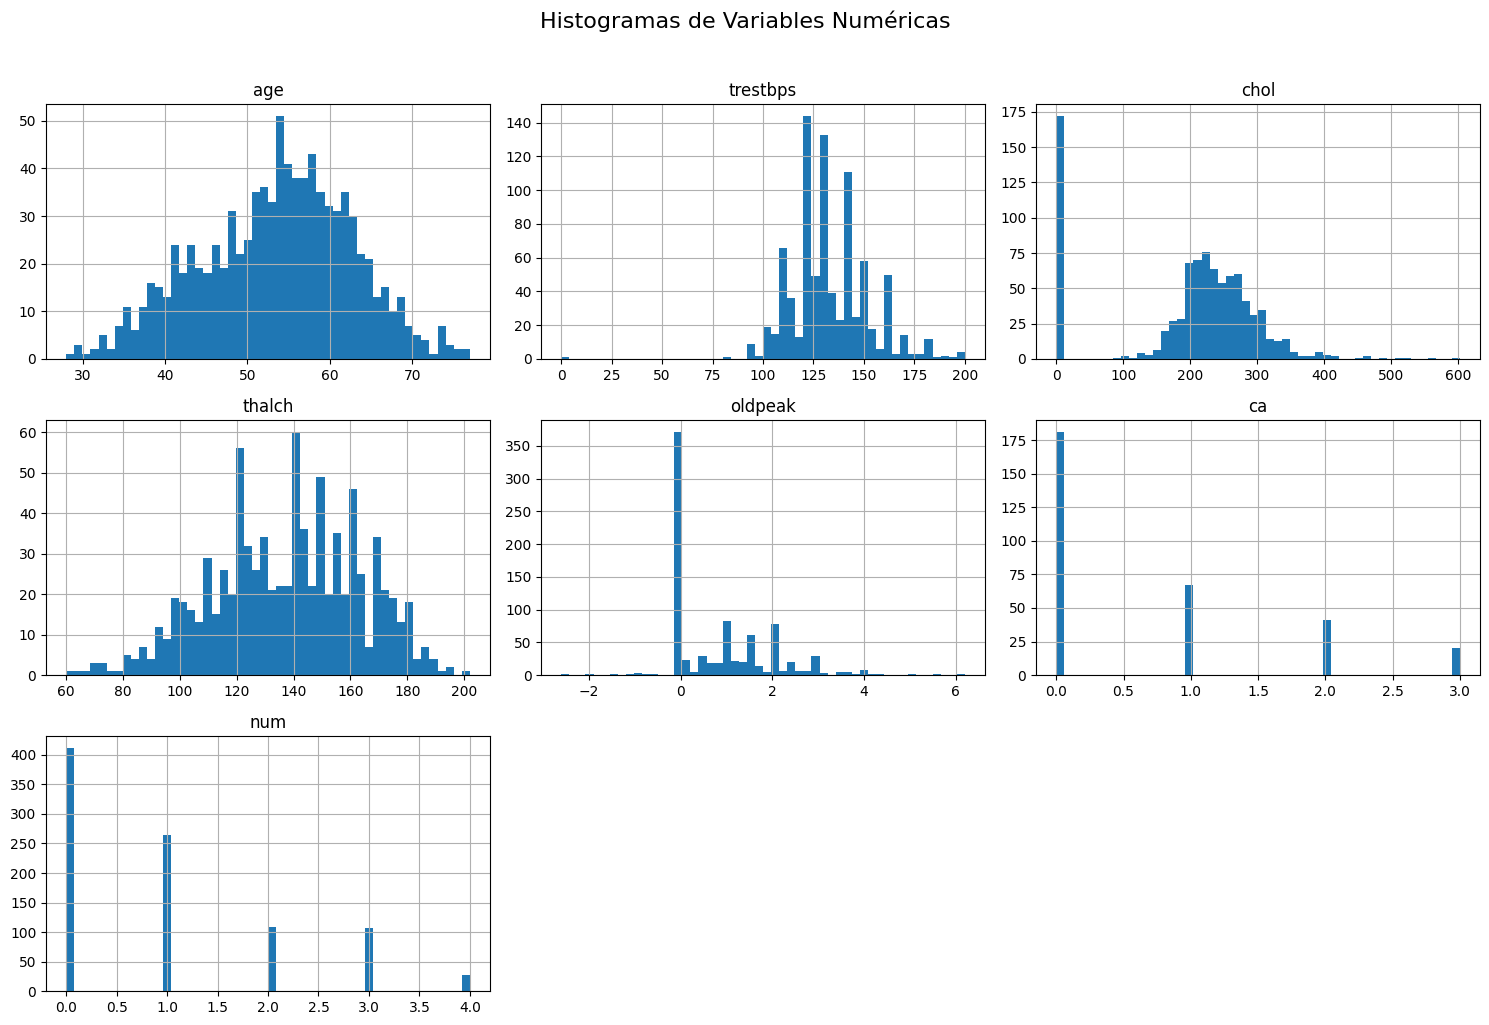

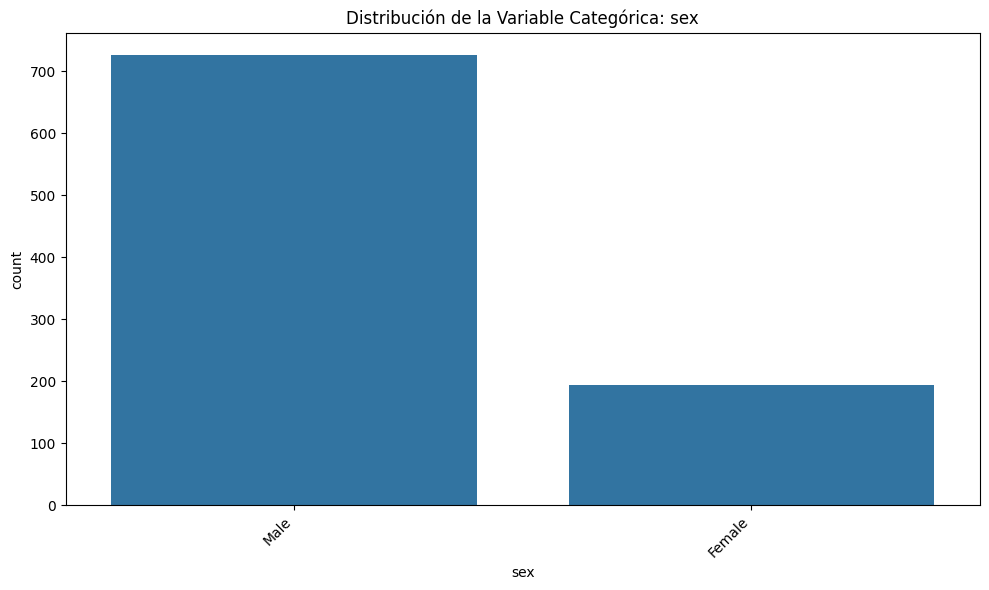

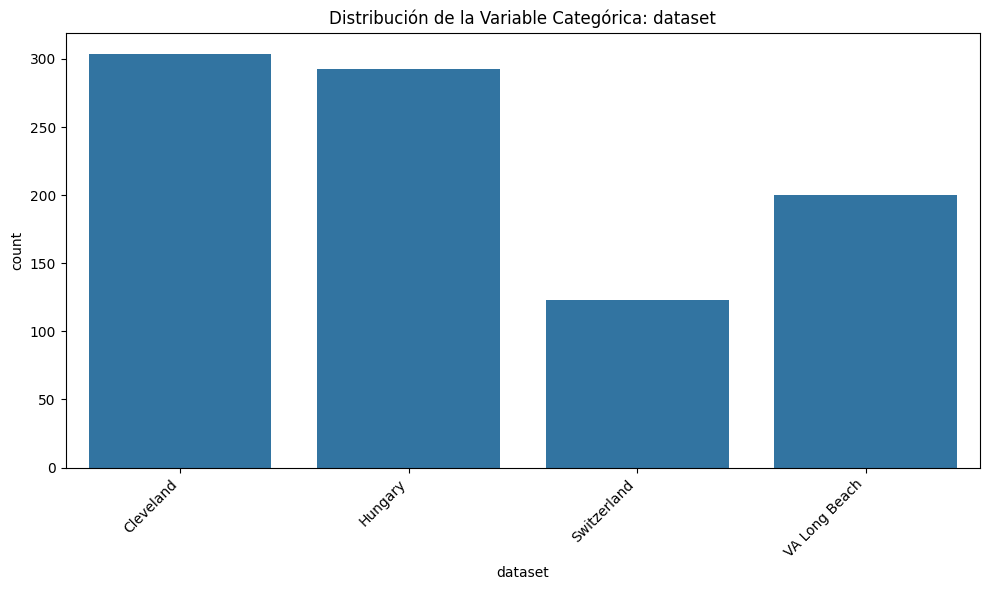

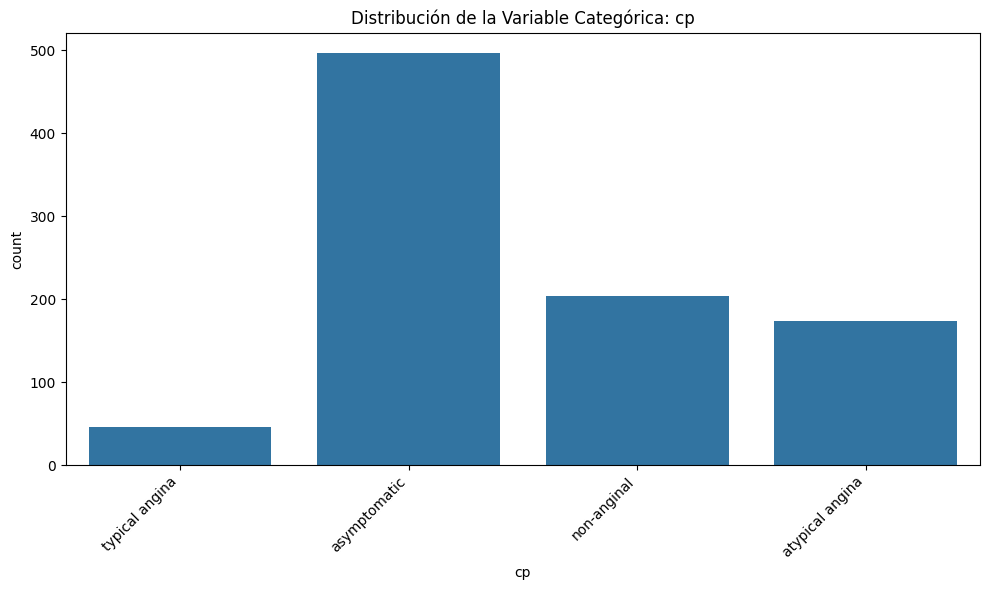

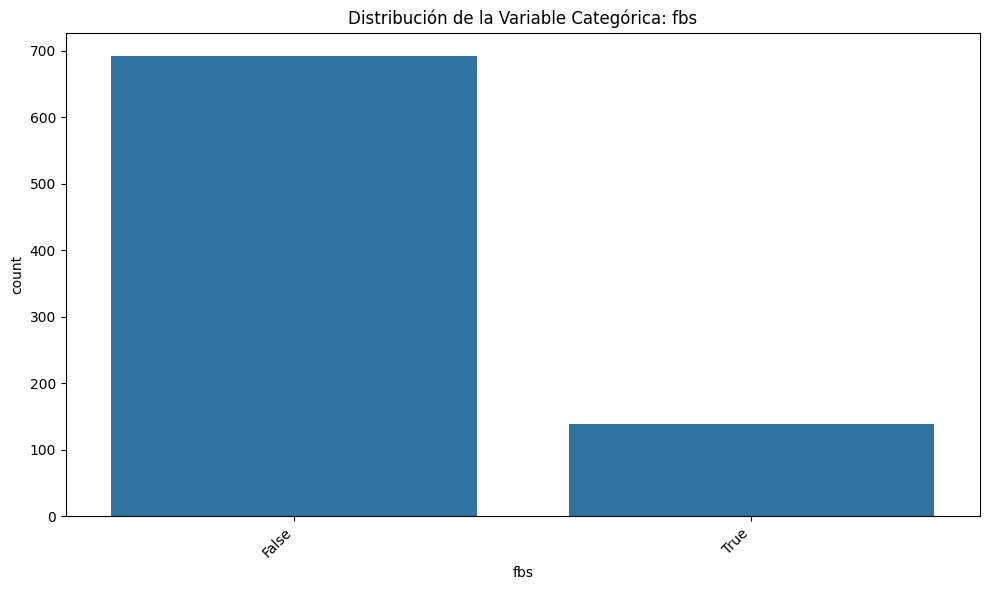

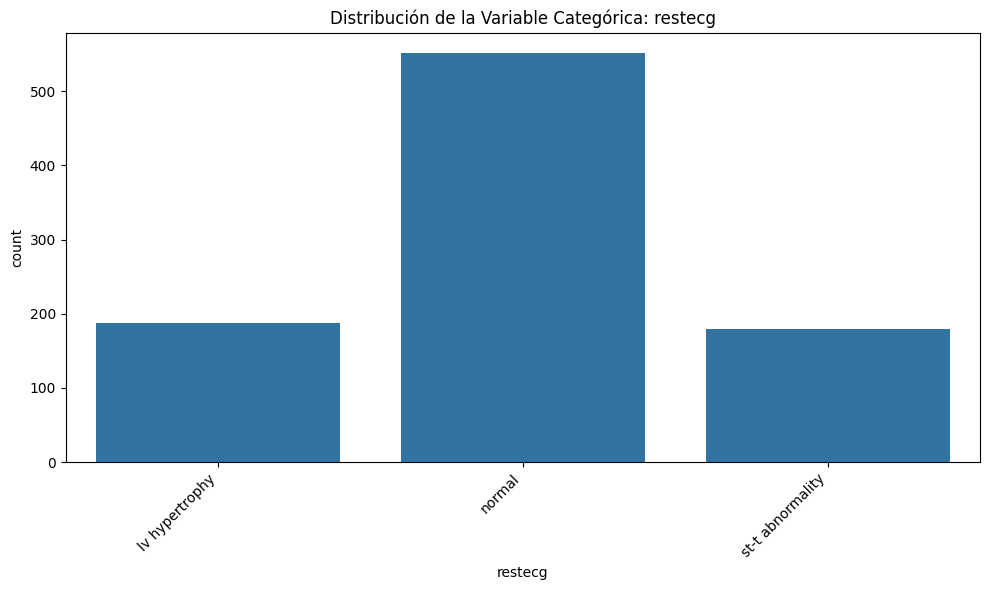

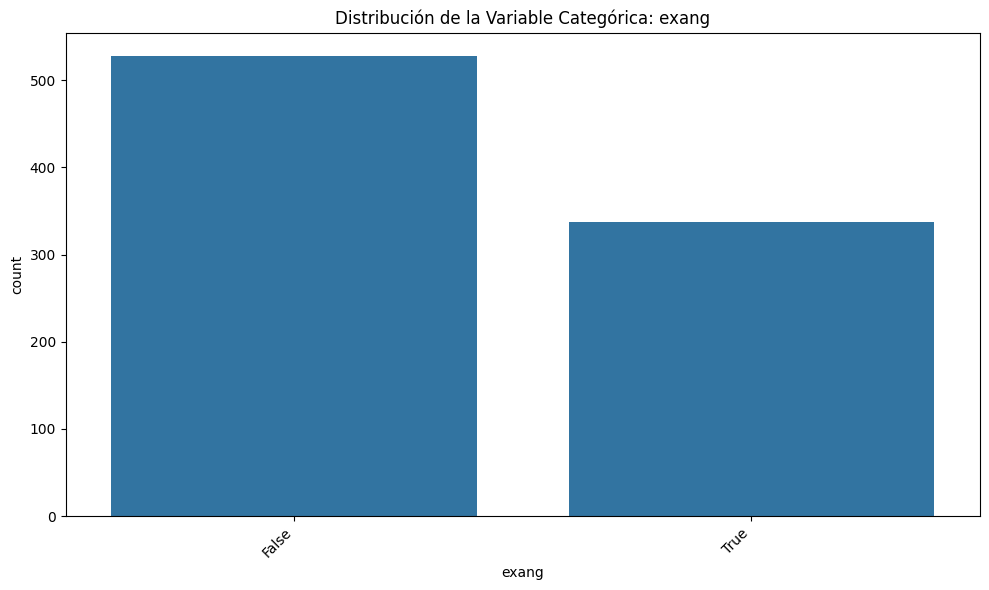

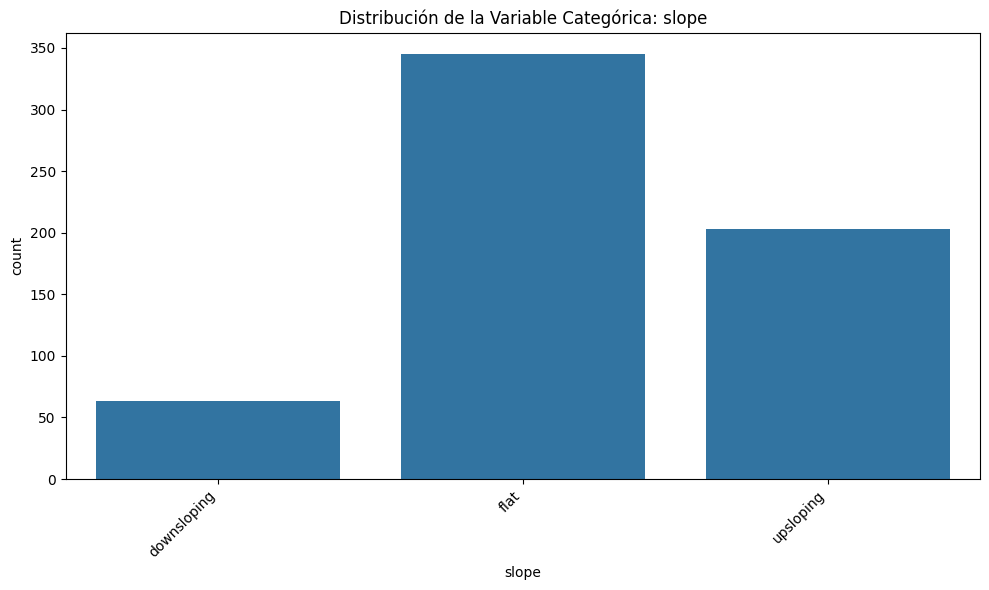

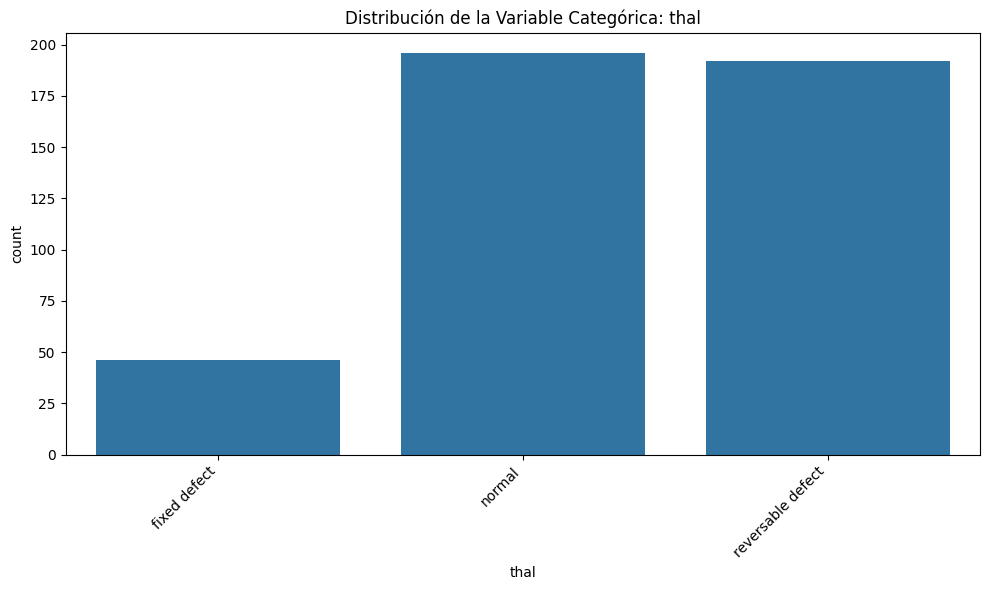

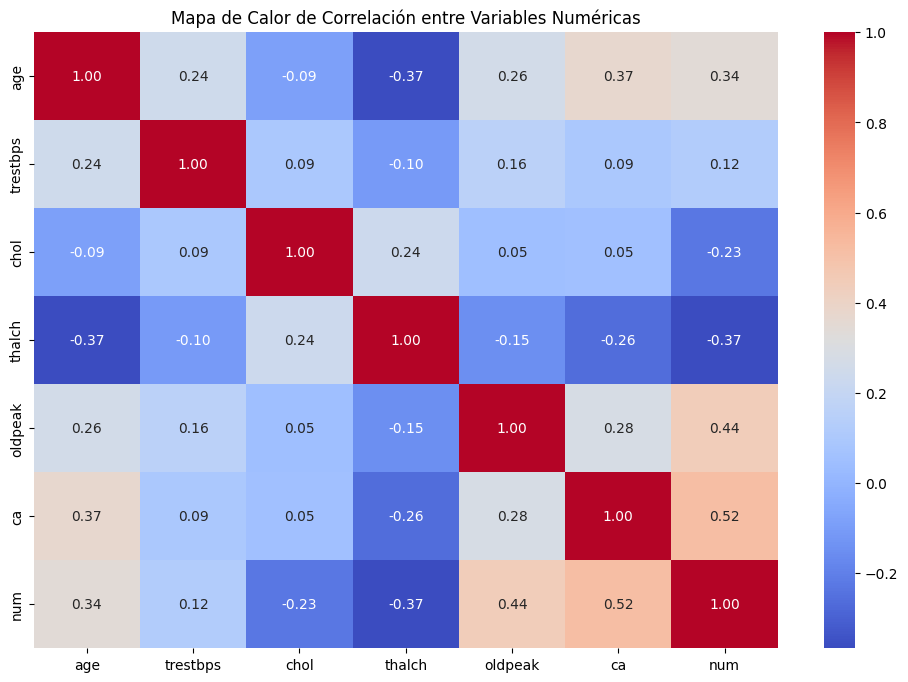

<Figure size 1500x1000 with 0 Axes>

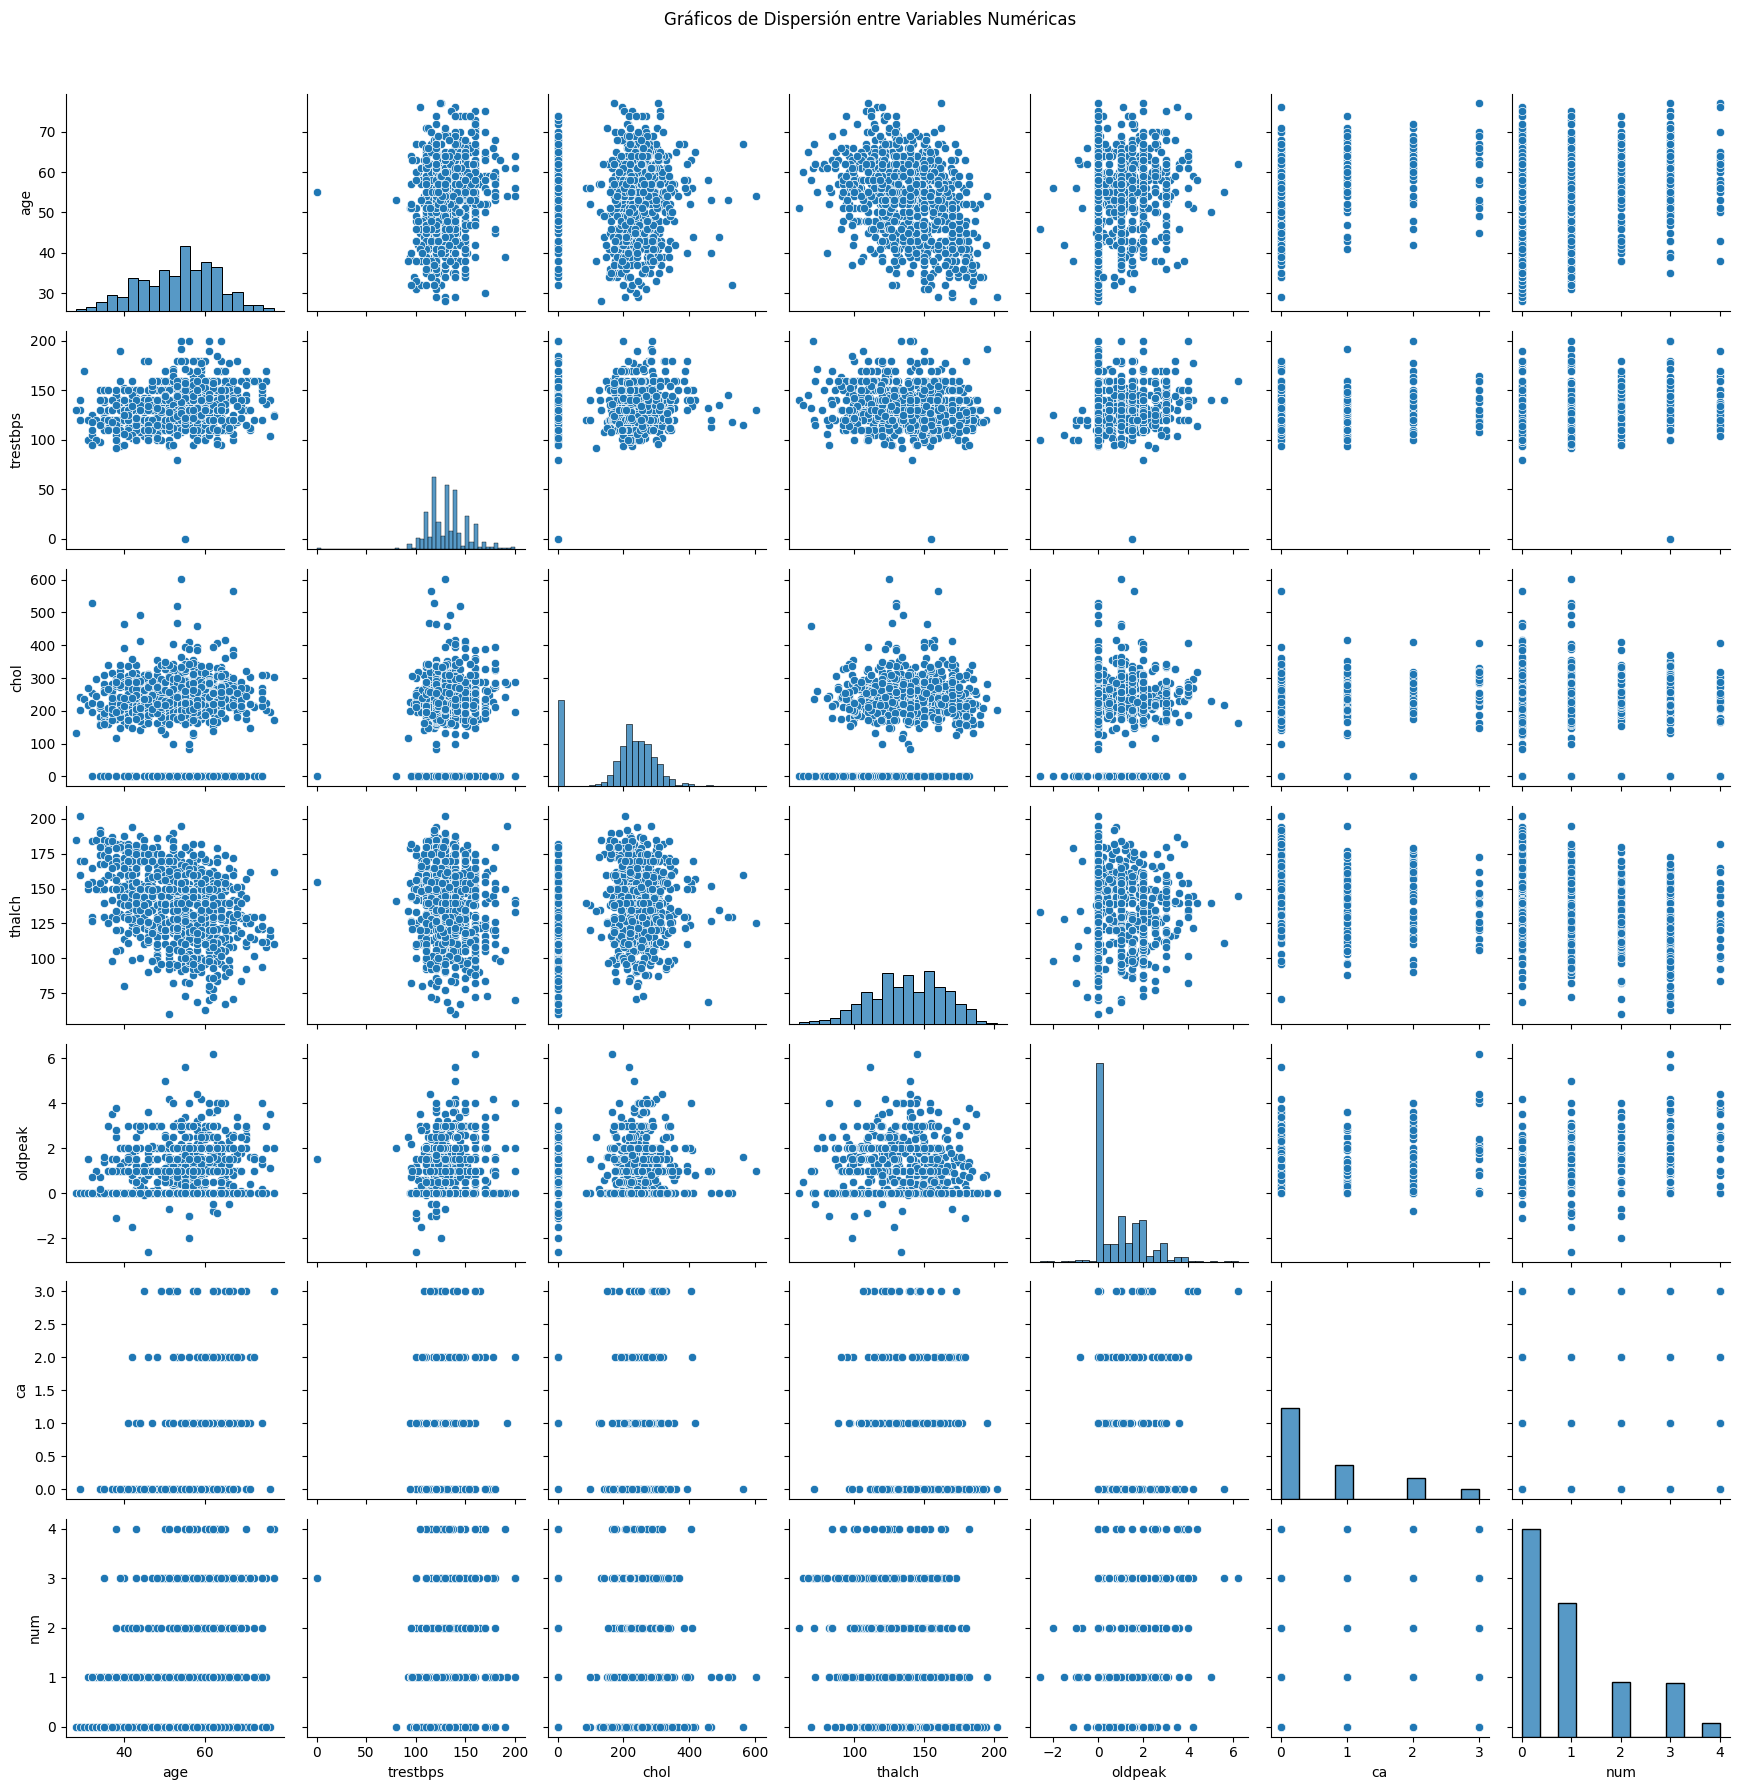

In [26]:
# Crear histogramas para variables numéricas
df[numerical_cols].hist(figsize=(15, 10), bins=50)
plt.suptitle('Histogramas de Variables Numéricas', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

# Crear gráficos de barras para variables categóricas
categorical_cols_for_plot = [col for col in categorical_cols if df[col].nunique() < 50]

if categorical_cols_for_plot:
    for col in categorical_cols_for_plot:
        plt.figure(figsize=(10, 6))
        sns.countplot(data=df, x=col)
        plt.title(f'Distribución de la Variable Categórica: {col}')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()
else:
    print("No hay variables categóricas con un número manejable de valores únicos para graficar.")

# Crear un mapa de calor para visualizar las correlaciones entre las variables numéricas
plt.figure(figsize=(12, 8))
correlation_matrix = df[numerical_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Mapa de Calor de Correlación entre Variables Numéricas')
plt.show()

# Crear gráficos de dispersión para identificar posibles relaciones entre variables numéricas
plt.figure(figsize=(15, 10))
sns.pairplot(df[numerical_cols])
plt.suptitle('Gráficos de Dispersión entre Variables Numéricas', y=1.02)
plt.tight_layout()
plt.show()

Calcular estadísticas descriptivas

In [27]:
print("\nEstadísticas descriptivas detalladas por columna:")
print("\nResumen general de estadísticas descriptivas:")
print(df.describe(include='all'))


Estadísticas descriptivas detalladas por columna:

Resumen general de estadísticas descriptivas:
               age   sex    dataset            cp    trestbps        chol  \
count   920.000000   920        920           920  861.000000  890.000000   
unique         NaN     2          4             4         NaN         NaN   
top            NaN  Male  Cleveland  asymptomatic         NaN         NaN   
freq           NaN   726        304           496         NaN         NaN   
mean     53.510870   NaN        NaN           NaN  132.132404  199.130337   
std       9.424685   NaN        NaN           NaN   19.066070  110.780810   
min      28.000000   NaN        NaN           NaN    0.000000    0.000000   
25%      47.000000   NaN        NaN           NaN  120.000000  175.000000   
50%      54.000000   NaN        NaN           NaN  130.000000  223.000000   
75%      60.000000   NaN        NaN           NaN  140.000000  268.000000   
max      77.000000   NaN        NaN           NaN  200.

Valores Faltantes y Outliers:

In [33]:
# Identificar columnas numéricas y categóricas con valores faltantes
numerical_cols_with_missing = df[numerical_cols].columns[df[numerical_cols].isnull().any()].tolist()
categorical_cols_with_missing = df[categorical_cols].columns[df[categorical_cols].isnull().any()].tolist()

print("Columnas numéricas con valores faltantes:", numerical_cols_with_missing)
print("Columnas categóricas con valores faltantes:", categorical_cols_with_missing)

# Imputar valores faltantes
# Para columnas numéricas, usar el promedio
for col in numerical_cols_with_missing:
    df[col].fillna(df[col].mean(), inplace=False)

# Para columnas categóricas, usar la moda
for col in categorical_cols_with_missing:
    df[col].fillna(df[col].mode()[0], inplace=False)

print("\nCantidad de datos nulos después de la imputación:")
print(df.isnull().sum())

Columnas numéricas con valores faltantes: ['trestbps', 'chol', 'thalch', 'oldpeak', 'ca']
Columnas categóricas con valores faltantes: ['fbs', 'restecg', 'exang', 'slope', 'thal']

Cantidad de datos nulos después de la imputación:
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64


/tmp/ipython-input-33-877227269.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col].fillna(df[col].mode()[0], inplace=False)


In [37]:
# Crear una copia del DataFrame para la imputación
df_imputed = df.copy()

# Identificar columnas numéricas y categóricas con valores faltantes
numerical_cols_with_missing = df_imputed[numerical_cols].columns[df_imputed[numerical_cols].isnull().any()].tolist()
categorical_cols_with_missing = df_imputed[categorical_cols].columns[df_imputed[categorical_cols].isnull().any()].tolist()

print("Columnas numéricas con valores faltantes:", numerical_cols_with_missing)
print("Columnas categóricas con valores faltantes:", categorical_cols_with_missing)

# Imputar valores faltantes en la copia del DataFrame
# Para columnas numéricas, usar la media
for col in numerical_cols_with_missing:
    df_imputed[col].fillna(df_imputed[col].mean(), inplace=True)

# Para columnas categóricas, usar la moda
for col in categorical_cols_with_missing:
    df_imputed[col].fillna(df_imputed[col].mode()[0], inplace=True)

print("\nCantidad de datos nulos en el DataFrame imputado:")
print(df_imputed.isnull().sum())

df = df_imputed.copy()

Columnas numéricas con valores faltantes: []
Columnas categóricas con valores faltantes: []

Cantidad de datos nulos en el DataFrame imputado:
age         0
sex         0
dataset     0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64


In [ ]:
# Los datos outliers identificados se encuentran en las columnas de 'ca', 'oldpeak', 'thalch', 'chol' y 'trestbps'. No afectan el estudio, ya que es un dato particular de la muestra. No requiere ser tratado.

##Resumen de Hallazgos:


El resumen de los principales hallazgos del Análisis Exploratorio de Datos (EDA) para el conjunto de datos de enfermedades cardíacas es el siguiente:

**Características Principales del Conjunto de Datos:**

* **Origen:** El dataset proviene de Kaggle y contiene información sobre enfermedades cardíacas.
* **Tamaño:** El dataset contiene 920 filas y 15 columnas después de eliminar la columna 'id'.
* **Variables:** El dataset incluye variables numéricas como 'age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', y 'num'. Las variables categóricas son 'sex', 'dataset', 'cp', 'fbs', 'restecg', 'exang', 'slope', y 'thal'.

**Hallazgos Clave del EDA:**

* **Valores Faltantes:** Se encontraron valores nulos en varias columnas, incluyendo 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', y 'thal'.
* **Valores Únicos:** Las columnas categóricas tienen un número limitado de valores únicos. Las columnas numéricas tienen una amplia gama de valores únicos.
* **Valores Duplicados:** Se encontraron 2 filas duplicadas en el dataset.
* **Inconsistencias en Datos Categóricos:** No se identificaron inconsistencias obvias en los datos categóricos.
* **Outliers:** Se detectaron outliers en las columnas numéricas 'trestbps', 'chol', 'thalch', 'oldpeak', y 'ca' utilizando el método IQR. Se determinó que estos outliers son datos particulares de la muestra y no requieren tratamiento en este momento.
* **Distribuciones Histogramas y Gráficos de Barras:**
  * Los histogramas muestran la distribución de las variables numéricas.
  * Los gráficos de barras muestran la distribución de las variables categóricas.
* **Correlaciones:** El mapa de calor de correlación entre las variables numéricas muestra diferentes grados de correlación entre las variables. 'age', 'oldpeak', y 'ca', así como 'num' muestran correlaciones positivas entre sí. 'thalch' muestra correlaciones negativas con 'age', 'oldpeak', 'ca', y 'num'.

**Desafíos Únicos del Conjunto de Datos:**

* **Valores Faltantes:** La presencia de valores faltantes en múltiples columnas requerirá estrategias de imputación o eliminación antes de construir modelos.
* **Outliers:** Aunque no se tratan, la presencia de outliers debe ser considerada al interpretar los resultados del modelo.
* **Balance de Clases:** La variable objetivo 'num', que representa la presencia de enfermedad cardíaca, podría presentar un desbalance de clases que debería ser considerado en el modelado.

En resumen, el EDA ha proporcionado una buena comprensión del conjunto de datos, revelando su estructura, la presencia de valores faltantes y duplicados, la presencia de outliers no problemáticos, y las distribuciones y correlaciones de las variables. Los principales desafíos identificados son el manejo de los valores faltantes y el posible desbalance de clases en la variable objetivo.

##Parte 3: Preprocesamiento de Datos
Uso de ColumnTransformer y Pipeline

In [38]:
# Cargar el conjunto de datos
X = df.drop('num', axis=1)
y = df['num']

# Transformar variable y a numérica
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Seleccionar columnas numéricas para escalar
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

# Identificar las columnas categóricas
categorical_features = X.select_dtypes(include='object').columns.tolist()

# Crear transformadores para cada subconjunto de columnas
# Escalar las características numéricas
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Realizar transformaciones necesarias para las características categóricas
# Usar OneHotEncoder para variables nominales
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

# Crear un ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
],
    remainder='passthrough'
)

##Parte 4: Implementación de modelo XGBoost

##Modelo de XGBoost

In [ ]:
# Crear pipeline para XGBoost
pipeline_xgb = Pipeline(steps=[('preprocessor', preprocessor),
                                     ('classifier', XGBClassifier(random_state=42))])

# Evaluación inicial con Cross-Validation
print("Evaluación inicial con Cross-Validation para XGBoost Classifier:")
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=42)

# Métricas de clasificación para cross-validation
cv_results_basic = cross_val_score(pipeline_xgb, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
print(f"Accuracy (CV): {cv_results_basic.mean():.4f} (+/- {cv_results_basic.std():.4f})")

# Entrenar el modelo con hiperparámetros básicos y evaluar en el conjunto de prueba
pipeline_xgb.fit(X_train, y_train)
y_pred = pipeline_xgb.predict(X_test)
y_proba = pipeline_xgb.predict_proba(X_test)


# Métricas de evaluación en el conjunto de prueba
accuracy = accuracy_score(y_test, y_pred)
# Average='weighted' para multiclass
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')
roc_auc = roc_auc_score(y_test, y_proba, multi_class='ovr')


print("\nMétricas de evaluación para XGBoost Classifier en el conjunto de prueba:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"ROC-AUC (OvR): {roc_auc:.4f}")

# Optimización de hiperparámetros con GridSearchCV
print("\nOptimizando Hiperparámetros con GridSearchCV para XGBoost Classifier:")
param_grid_xgb = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__learning_rate': [0.01, 0.1, 0.2],
    'classifier__max_depth': [3, 5, 7],
    'classifier__subsample': [0.7, 0.8, 0.9],
    'classifier__colsample_bytree': [0.7, 0.8, 0.9]
}

# Métrica para multiclases con GridSearchCV scoring
grid_search_xgb = GridSearchCV(pipeline_xgb, param_grid_xgb, cv=cv, scoring='roc_auc_ovr_weighted', n_jobs=-1)
grid_search_xgb.fit(X_train, y_train)

print(f"Mejores Parámetros con GridSearchCV: {grid_search_xgb.best_params_}")
print(f"Mejor valor Cross-Validation ROC-AUC con GridSearchCV: {grid_search_xgb.best_score_:.4f}")

# Evaluar el mejor modelo en el conjunto de prueba
best_xgb_model_gs = grid_search_xgb.best_estimator_
y_pred_gs = best_xgb_model_gs.predict(X_test)
y_proba_gs = best_xgb_model_gs.predict_proba(X_test)

# Métricas de evaluación para el mejor modelo con GridSearchCV
accuracy_gs = accuracy_score(y_test, y_pred_gs)
# Use average='weighted' for multiclass
precision_gs = precision_score(y_test, y_pred_gs, average='weighted')
recall_gs = recall_score(y_test, y_pred_gs, average='weighted')
f1_gs = f1_score(y_test, y_pred_gs, average='weighted')
roc_auc_gs = roc_auc_score(y_test, y_proba_gs, multi_class='ovr')


print("\nMétricas de evaluación para el mejor modelo con GridSearchCV para XGBoost Classifier:")
print(f"Accuracy: {accuracy_gs:.4f}")
print(f"Precision: {precision_gs:.4f}")
print(f"Recall: {recall_gs:.4f}")
print(f"F1-Score: {f1_gs:.4f}")
print(f"ROC-AUC (OvR): {roc_auc_gs:.4f}")


# Comparar resultados
print("\nComparación de resultados:")
print(f"Modelo Básico - ROC-AUC (OvR): {roc_auc:.4f}")
print(f"Modelo Optimizado (GridSearchCV) - ROC-AUC (OvR): {roc_auc_gs:.4f}")

Evaluación inicial con Cross-Validation para XGBoost Classifier:
Accuracy (CV): 0.5626 (+/- 0.0454)

Métricas de evaluación para XGBoost Classifier en el conjunto de prueba:
Accuracy: 0.6576
Precision: 0.6315
Recall: 0.6576
F1-Score: 0.6360
ROC-AUC (OvR): 0.8396

Optimizando Hiperparámetros con GridSearchCV para XGBoost Classifier:


##Comparación de Modelos:

In [ ]:
# Resultados de cada modelo
results = {
     'LGBM': {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    },
    'LGBM (GridSearchCV)': {
        'Accuracy': accuracy_gs,
        'Precision': precision_gs,
        'Recall': recall_gs,
        'F1-Score': f1_gs,
        'ROC-AUC': roc_auc_gs
    }
}

# Crear DataFrame para comparación
results_xgb = pd.DataFrame(results).T

# Ordenar por ROC-AUC para ver el mejor rendimiento
results_xgb_sorted = results_xgb.sort_values(by='ROC-AUC', ascending=False)

print("Comparación de Modelos (Ordenado por ROC-AUC):")
display(results_xgb_sorted)

# Identidical el mejor modelo basado en ROC-AUC
best_model_name_roc_auc = results_xgb_sorted.index[0]
best_model_roc_auc_score = results_xgb_sorted.iloc[0]['ROC-AUC']

print(f"\nEl mejor modelo basado en ROC-AUC es: {best_model_name_roc_auc} con un ROC-AUC de {best_model_roc_auc_score:.4f}")

# Identificar el mejor modelo basado en Accuracy
best_model_name_accuracy = results_xgb.sort_values(by='Accuracy', ascending=False).index[0]
best_model_accuracy_score = results_xgb.sort_values(by='Accuracy', ascending=False).iloc[0]['Accuracy']

print(f"\nEl mejor modelo basado en Accuracy del conjunto es: {best_model_name_accuracy} con Accuracy de {best_model_accuracy_score:.4f}")